In [58]:
import torch
from skfp.model_selection import scaffold_train_valid_test_split
import json
from protlig.helper import load_dataset

def make_split(smiles, valid_size, test_size, path='../data/split_scaffold.json'):
    tr, va, te = scaffold_train_valid_test_split(
        data=smiles,
        train_size=1.0 - valid_size - test_size,
        valid_size=valid_size,
        test_size=test_size,
        return_indices=True
    )

    split = {
        'train': list(map(int, tr)),
        'val': list(map(int, va)),
        'test': list(map(int, te))
    }

    with open(path, 'w') as fh:
        json.dump(split, fh)
    return split

data = load_dataset()
smiles = data['SMILES'].values
labels = torch.tensor(data['label'].values, dtype=torch.float32)
split = make_split(smiles, 0.1, 0.1)

In [59]:
import numpy as np

class TargetScaler:
    def __init__(self, y_train):
        self.mean = float(torch.mean(y_train))
        self.sd = float(torch.std(y_train))

    def forward(self, y):
        return (y - self.mean) / self.sd
    
    def inverse(self, z):
        return z * self.sd + self.mean

target_scaler = TargetScaler(labels)
target_scaler.inverse(labels)

tensor([ -4.6644,  -9.9684,  -7.3688,  ...,  -9.5302,  -9.7168, -12.5302])

In [62]:
from protlig.helper import iterate_minibatches
from sklearn.metrics import root_mean_squared_error

def train(model, train_graphs, val_graphs, lr, epochs, scaler, patience, seed=1):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_val, best_state, best_epoch, history = np.inf, None, -1, []

    for e in range(1, epochs + 1):
        model.train()
        train_loss, n_seen = 0.0, 0

        for x, ei, batch, y in iterate_minibatches(
            train_graphs, 64, seed + e
        ):
            n_graphs = int(batch.max() + 1)
            opt.zero_grad()
            out = model(x, ei, batch, n_graphs).view(-1)
            z = scaler.forward(y).view(-1)
            loss = ((out - z) ** 2).mean()
            loss.backward()
            opt.step()

            n_seen += n_graphs
            train_loss += float(loss) * n_graphs
        
        train_loss /= n_seen

        # collect training and val data

        preds_train, ys_train = predict(model, train_graphs)
        train_rmse = root_mean_squared_error(scaler.inverse(preds_train), ys_train)
        
        preds_val, ys_val = predict(model, val_graphs)
        val_loss = ((preds_val - scaler.forward(ys_val)) ** 2).mean()
        val_rmse = root_mean_squared_error(scaler.inverse(preds_val), ys_val)

        history.append((e, val_loss, train_loss, val_rmse, train_rmse))

        if val_rmse < best_val - 1e-6:
            best_val, best_epoch = val_rmse, e
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        elif e - best_epoch >= patience:
            print(f"  early stop at epoch {e} (best epoch {best_epoch})")
            break

    model.load_state_dict(best_state)
    return history, best_epoch, best_val

@torch.no_grad()
def predict(model, graphs, batch_size=256):
    preds, ys = [] , []
    model.eval()
    for x, ei, batch, y in iterate_minibatches(graphs, batch_size, shuffle=False):
        out = model(x, ei, batch, int(batch.max()) + 1).view(-1)
        preds.append(out)
        ys.append(y.view(-1))
    model.train()

    return torch.cat(preds).numpy(), torch.cat(ys).numpy()

In [73]:
from protlig.helper import mol_to_graph, GCNConv

data = load_dataset()
smiles, labels = data['SMILES'].values, data['label'].values
graphs = [mol_to_graph(s, l) for s, l in zip(smiles, labels)]

train_graphs = [g for i, g in enumerate(graphs) if i in split['train']]
val_graphs = [g for i, g in enumerate(graphs) if i in split['val']]
y_train = torch.tensor(labels[split['test']], dtype=torch.float32)

IN_DIMS = graphs[0][0].size(1)
HIDDEN_DIMS = 64
N_LAYERS = 2

lr = 1e-3
epochs = 300
patience = 40
batch_size = 64
seed = 0
model = GCNConv(IN_DIMS, HIDDEN_DIMS, N_LAYERS)
scaler = TargetScaler(y_train)
history, best_epoch, best_val = train(model, train_graphs, val_graphs, lr, epochs, scaler, patience)

  early stop at epoch 138 (best epoch 98)


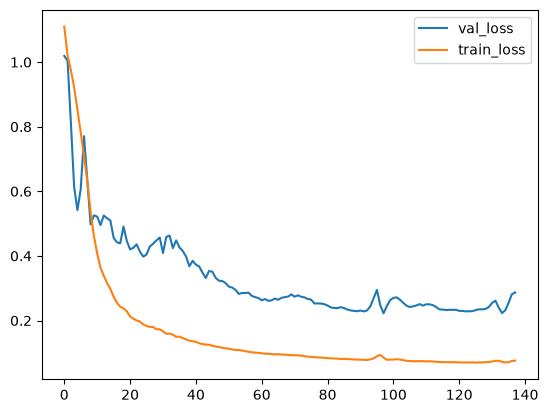

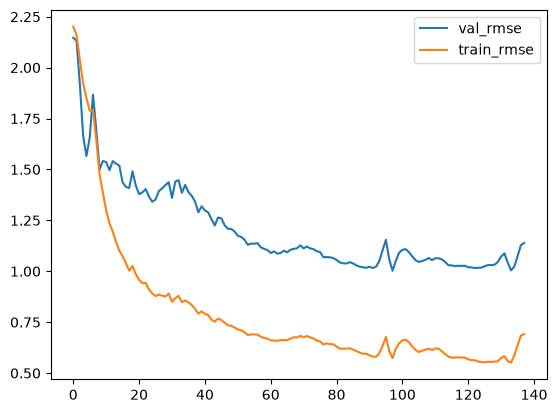

In [80]:
import numpy as np

hist = np.array(history)          # shape: (n_epochs, 5)

epochs     = hist[:, 0].astype(int)
val_loss   = hist[:, 1]
train_loss = hist[:, 2]
val_rmse   = hist[:, 3]
train_rmse = hist[:, 4]

import matplotlib.pyplot as plt

plt.plot(val_loss, label='val_loss')
plt.plot(train_loss, label='train_loss')
plt.legend()
plt.show()

plt.plot(val_rmse, label='val_rmse')
plt.plot(train_rmse, label='train_rmse')
plt.legend()


In [76]:
test_graphs = [g for i, g in enumerate(graphs) if i in split['test']]

def evaluate(model, graphs, scaler, y_train):
    zp, y_true = predict(model, graphs)
    y_pred = scaler.inverse(zp)
    model_rmse = root_mean_squared_error(y_true, y_pred)
    return {
        "model_rmse": model_rmse,
        "n": int(len(y_true)),
    }

evaluate(model, test_graphs, scaler, y_train)

{'model_rmse': 0.905686616897583, 'n': 112}